<h1><center>Diabetes Prediction</center></h1>

## Abstract
Diabetes is a chronic disease that occurs when the pancreas is no longer able to make insulin, or when the body cannot make good use of the insulin it produces. Learning how to use Machine Learning can help us predict Diabetes.

Keywords: python, seaborn, numpy, plotly, pandas, matplotlib, scikit-learning, multiple linear regression, polynomial regression, decision tree, random forest, regression, logistic regression, machine learning, supervised learning

## About this Project
This project seeks to better understand the various factors that affect diabetes and their relationship with each other.  The project will also use various machine learning techniques to predict various life expectancies by country and other indicators and provide the metrics needed to evaluate the predictions.

Core Objectives:
<li>The objective of this project is to classify whether someone has diabetes or not.</li>
<li>Dataset consists of several Medical Variables(Independent) and one Outcome Variable(Dependent)</li>
<li>The independent variables in this data set are :-'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin','BMI', 'DiabetesPedigreeFunction', 'Age'</li>
<li>The outcome variable value is either 1 or 0 indicating whether a person has diabetes(1) or not(0).</li>




## The Data
This dataset is a part of a large dataset held at the National Institute of Diabetes and Digestive and Kidney Diseases and was obtained through https://data.world/

The target variable is specified as "outcome", where 1 indicates a positive result of the diabetes test and 0 indicates a negative result.

A machine learning model is requested to be developed that can predict whether individuals have diabetes or not when their features are given. Before developing the model, performing the necessary data analysis and feature engineering steps are expected.

### There are 9 variables in the dataset:

<li>Pregnancies: Number of pregnancies.</li>
<li>Glucose: 2-hour plasma glucose concentration during an oral glucose tolerance test.</li>
<li>Blood Pressure: Blood Pressure (Diastolic) (mm Hg).</li>
<li>SkinThickness : Thickness of skin</li>
<li>Insulin: 2-Hour Serum Insulin (mu U/ml)</li>
<li>DiabetesPedigreeFunction: Function (2-hour plasma glucose concentration during an oral glucose tolerance test).</li>
<li>BMI: Body Mass Index (weight in kg/(height in meters)^2)</li>
<li>Age: Persons age(in years)</li>
<li>Outcome: Having diabetes status (1: diabetes, 0: no diabetes)</li>

## Importing Python libraries

In [1]:
# Import libraries
import os
import csv

# Import packages for EDA and Data Visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from matplotlib import pyplot

# Plotting
import plotly.graph_objects as go
from pandas.plotting import scatter_matrix

# Images
import dataframe_image as dfi
from IPython.display import Image

#Statistical Functions
from IPython.display import display, HTML
from scipy.stats import stats
from scipy.stats.mstats import winsorize

# Import Classes for Model Traning and Feature Exploration / Engineering 
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split, cross_val_score
from scipy.stats import mstats
from sklearn.preprocessing import QuantileTransformer

# Linear Models & Metrics
import numpy as np
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, accuracy_score, \
    classification_report, roc_auc_score, roc_curve
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from ydata_profiling import ProfileReport

# K Nearest Neighbour
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV

# Naive Bayes
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV

#Support Vector Machine
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score

# Decision Tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier 
from sklearn.tree import export_graphviz
from io import StringIO
import pydotplus
import six
import sys
sys.modules['sklearn.externals.six'] = six
from IPython.display import Image 

from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
dt = DecisionTreeClassifier(random_state=42)

SEED = 42  # random seed for modeling




## Loading the Dataset

In [2]:
# GLOBAL VARIABLES
# Load data into pandas data frame
pd.set_option('display.width', 480)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option("display.max_columns", 20)
df = pd.read_csv('diabetes.csv')
feature_cols = ['Pregnancies', 'Glucose','BloodPressure','SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
num_cols = [col for col in df.columns if df[col].dtypes != "O"]

wins_df = pd.DataFrame()  # Winsorized dataframe holder

wins_dict = {}  # Winsorized feature dictionary
#feature_vars = list(df.columns)[:8]  # List of numerical features

# Check for directory called charts, create it if it doesn't exist
directory = "charts"

if not os.path.exists(directory):
    os.makedirs(directory)
    print(f"Directory '{directory}' created.")
else:
    print(f"Directory '{directory}' already exists.")

Directory 'charts' already exists.


## Exploratory Data Analysis

In exploratory data analysis, the type of the variables (e.g. integer or decimal) is first printed, the sum of the missing values (either null or na) is calculated, and it is found that no such value exists.
In addition, some statistical measures are calculated to understand their variation. Some of these statistical measures are the mean of each column, the median, the standard deviation, the percentages, etc.

### Understanding the Dataset

In [3]:
df.shape

(768, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [6]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


In [7]:
df.tail(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.900,0.171,63,0
764,2,122,70,27,0,36.800,0.340,27,0
765,5,121,72,23,112,26.200,0.245,30,0
766,1,126,60,0,0,30.100,0.349,47,1
767,1,93,70,31,0,30.400,0.315,23,0


In [8]:
# Write charts to image files
def view_df_to_image(text_body, file_name):
    df_styled = text_body.style.background_gradient()  # Style the text
    dfi.export(df_styled, 'charts/' + file_name + '.png')  # Create image of text
    
# Write dataframe info to images
dfi.export(pd.DataFrame(df.dtypes).style.background_gradient(), 'charts/Orig_Column_Headings.png')

text_body = df.head(5)
view_df_to_image(text_body, 'Head(5)')
df_styled = text_body.style.background_gradient()  # Style the text
dfi.export(df_styled, 'charts/' + 'Head(5)' + '.png')  # Create image of text

text_body = df.tail(5)
view_df_to_image(text_body, 'Tail(5)')
df_styled = text_body.style.background_gradient()  # Style the text
dfi.export(df_styled, 'charts/' + 'Tail(5)' + '.png')  # Create image of text

In [9]:
# Check for duplicate values
df.duplicated().any()

False

No duplicates found, we have a clean dataframe.

In [10]:
# Describe view stats on dataframe
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose,768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
BloodPressure,768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
SkinThickness,768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin,768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI,768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
DiabetesPedigreeFunction,768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age,768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome,768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


<b>Conclusion:</b> We observe that min value of some columns is 0 which cannot be possible medically.Hence in the data cleaning process we'll have to replace them with median/mean value depending on the distribution. Also in the max column we can see insulin levels as high as 846 with a mean of only 79.80. We have to treat outliers. Skinthickness also shows a large variance between the mean of 20.53 and the max of 99.

### Univariant Analysis (Five - Point Summary)

Now we will examine the distrubtion of all the attributes in the dataset by Outcome - the dark blue data points.

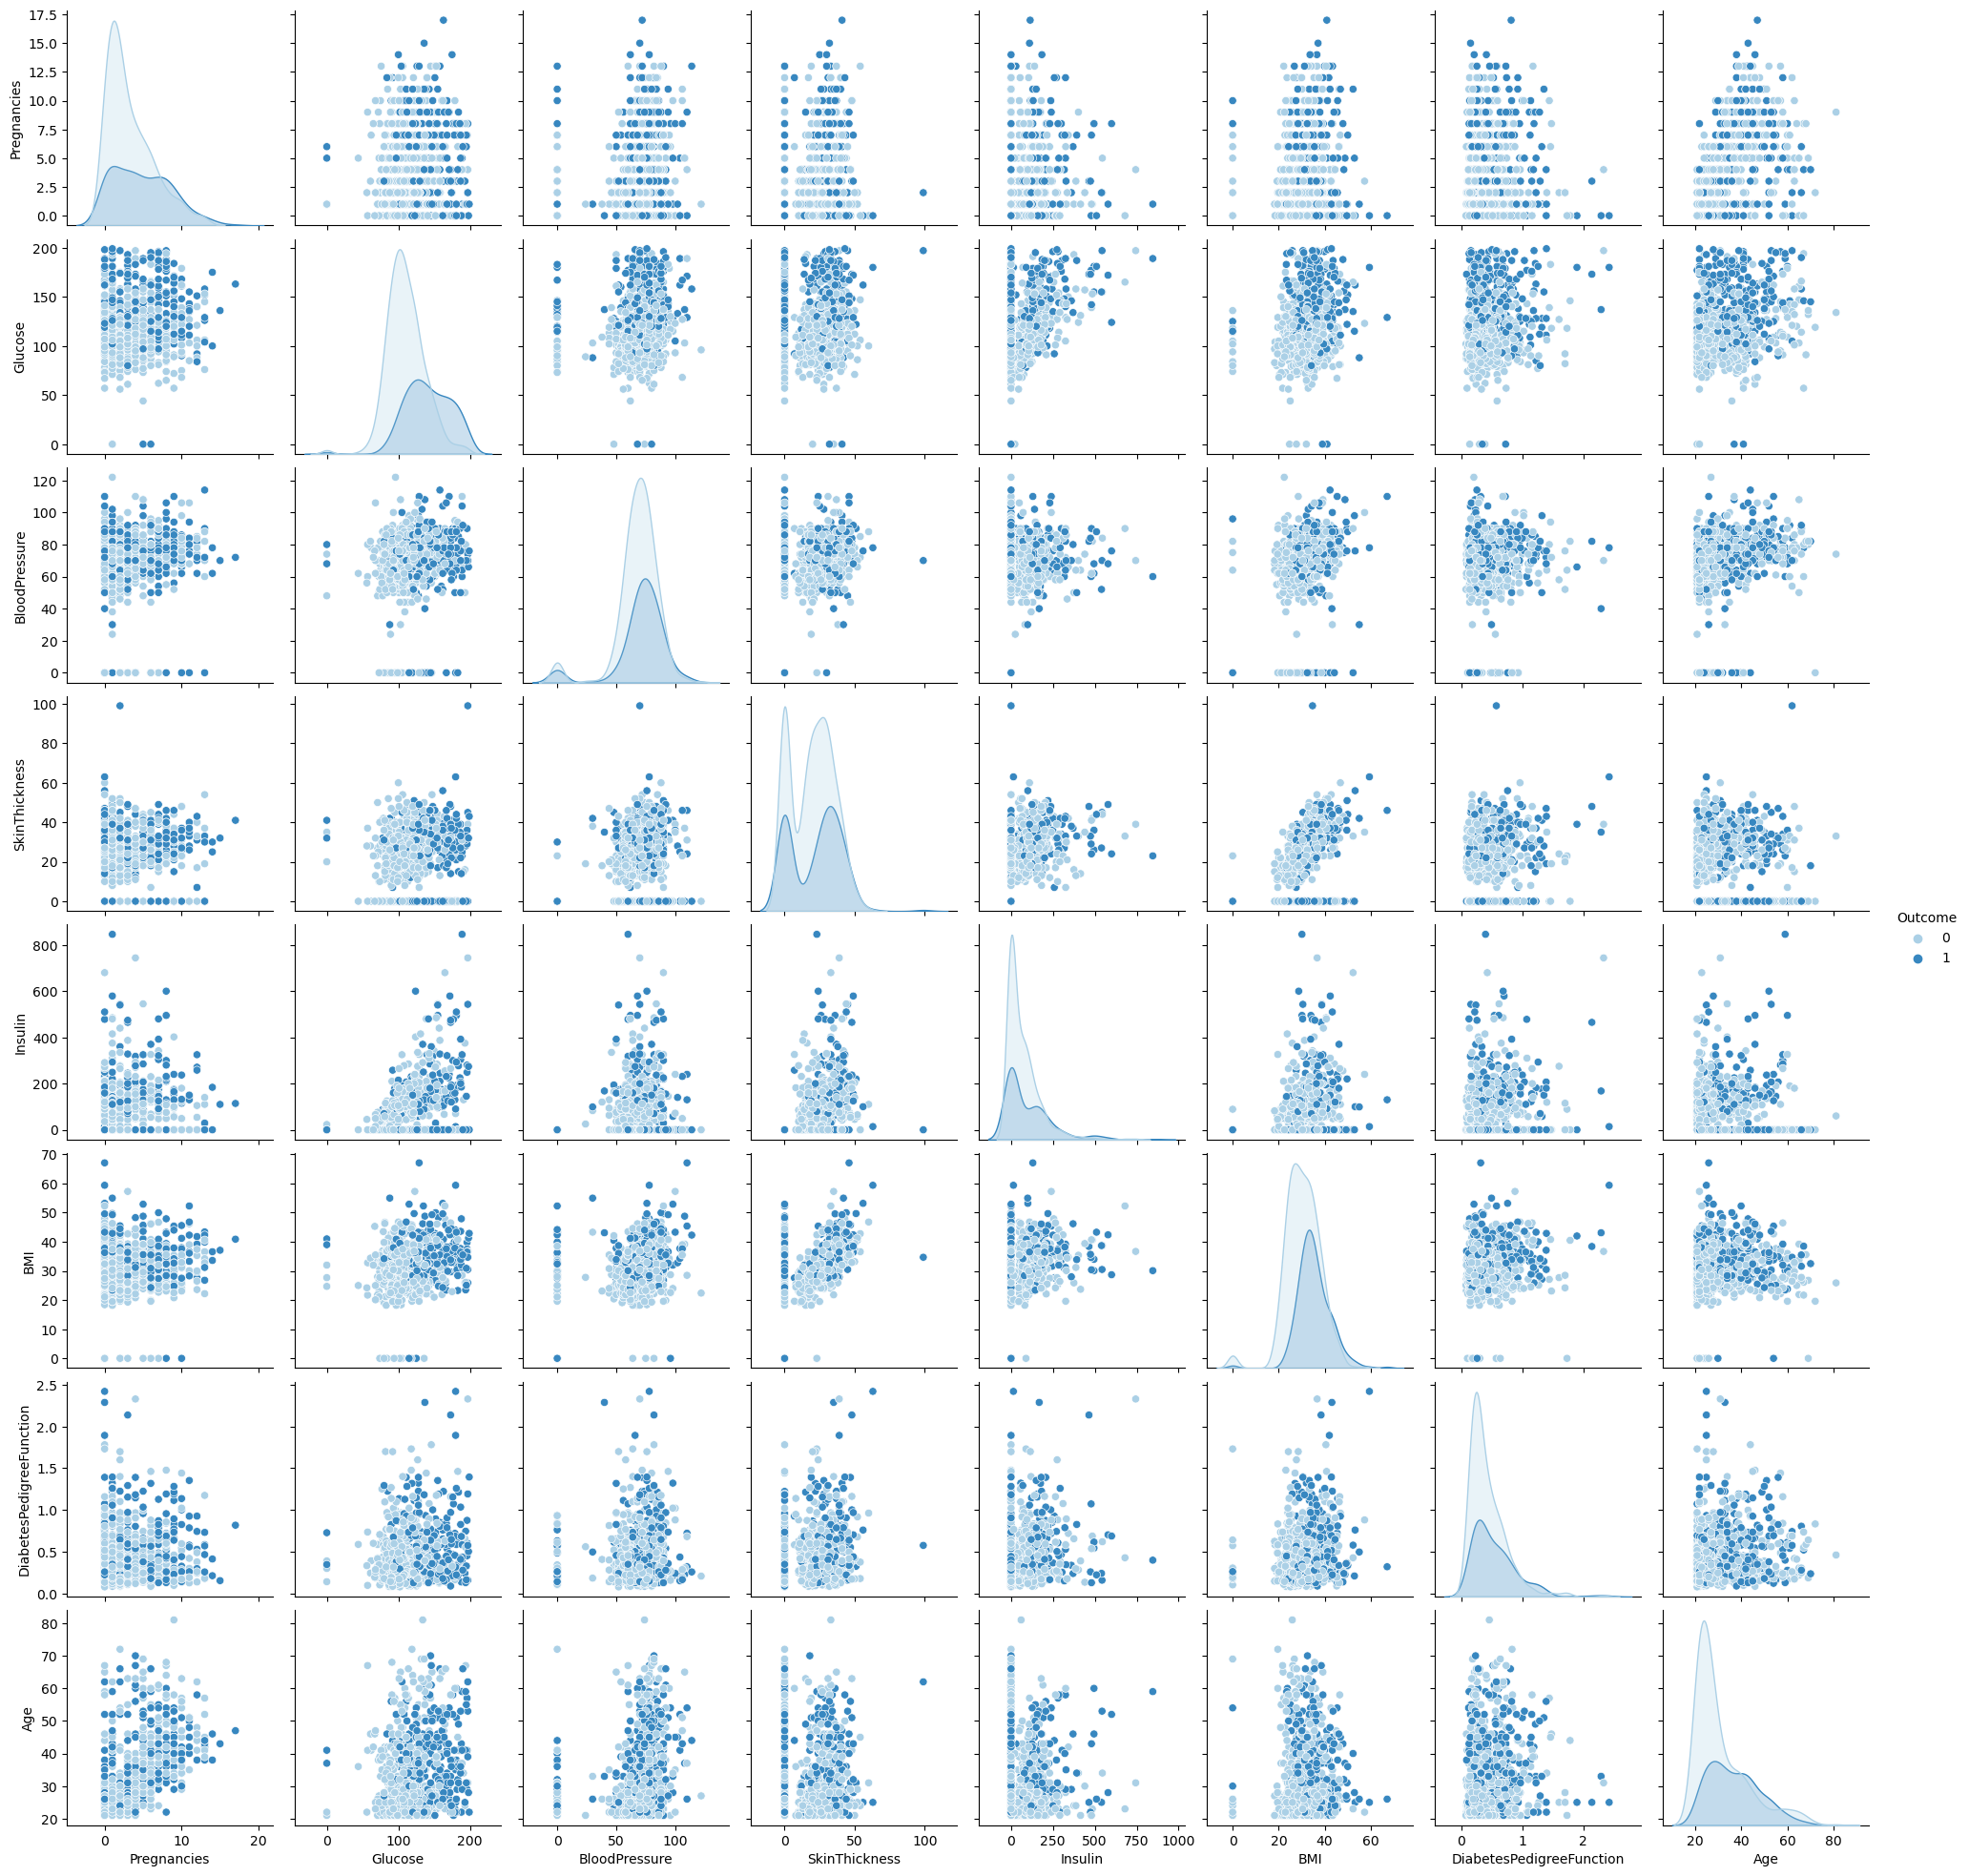

In [11]:
sns.pairplot(df, hue='Outcome', palette="Blues")
plt.show()

Here are a few observations:

<li>There are less younger women that have diabetes, compared to women in their 30s-50s.</li>
<li>Women that have diabetes have higher BMI.</li>
<li>Diabetes pedigree function is lower for women that have diabetes; Same thing with insulin & glucose.</li>
<li>Pregnacies are also lower among women that have diabetes.</li>
<li>There are outliers present in almost all of the attributes.</li>

<b>Note:</b> Women are those known to have had pregnacies

### Data Cleaning

<li>Dropping duplicate values</li>
<li>Checking NULL values</li>
<li>Checking for 0 value and replacing it. It isn't medically possible for some data record to have 0 value such as Blood Pressure or Glucose levels. Hence we replace them with the mean value of that particular column.</li>

#### Duplicate Records

In [12]:
#dropping duplicate values - checking if there are any duplicate rows and dropping if any
df=df.drop_duplicates()

## Null Summary
Missing values can exist when we have nulls, but there can also be erroneous missing values when the values appear to be inexplicit. Inexplicit nulls may require a more discretion when deciding how to deal with them as they may still represent actual data. "isnull" reveals that we have no null values.

In [13]:
# NULLS
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [14]:
#def null_summary():
na_values = df.isna().sum().reset_index()  # Find NA values
na_values.columns = ["Features", "Missing_Values"]
na_values["Missing_Percent"] = round(na_values.Missing_Values / len(df) * 100, 2)
print("Summarize NULLS: \n", na_values[na_values.Missing_Values > 0])

df_nulls = na_values[na_values.Missing_Values > 0]
dfi.export(pd.DataFrame(df_nulls).style.background_gradient(), 'charts/Summarize_Nulls.png')  # Print to image
df.info()  

Summarize NULLS: 
 Empty DataFrame
Columns: [Features, Missing_Values, Missing_Percent]
Index: []
<class 'pandas.core.frame.DataFrame'>
Int64Index: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 60.0 KB


Checking for 0 values in 5 columns, Age & DiabetesPedigreeFunction do not have have minimum 0 value so no need to replace, also number of pregnancies as 0 is possible as observed in df.describe

In [15]:
print(df[df['BloodPressure']==0].shape[0])
print(df[df['Glucose']==0].shape[0])
print(df[df['SkinThickness']==0].shape[0])
print(df[df['Insulin']==0].shape[0])
print(df[df['BMI']==0].shape[0])

35
5
227
374
11


<b>Conclusion:</b> Some of the columns have a skewed distribution, so the mean is more affected by outliers than the median. Glucose and Blood Pressure have normal distributions hence we replace 0 values in those columns by mean value. SkinThickness, Insulin,BMI have skewed distributions hence median is a better choice as it is less affected by outliers.

## Missing Value Imputation - Iterative Imputer

#### Before Imputation

With imputation we are looking for zero values in 4 specific columns - bloodPressure, BMI, glucose, and skinthickness as none of them should contains zero values. Columns like insulin and pregnancies may legitimately contain zero values. 

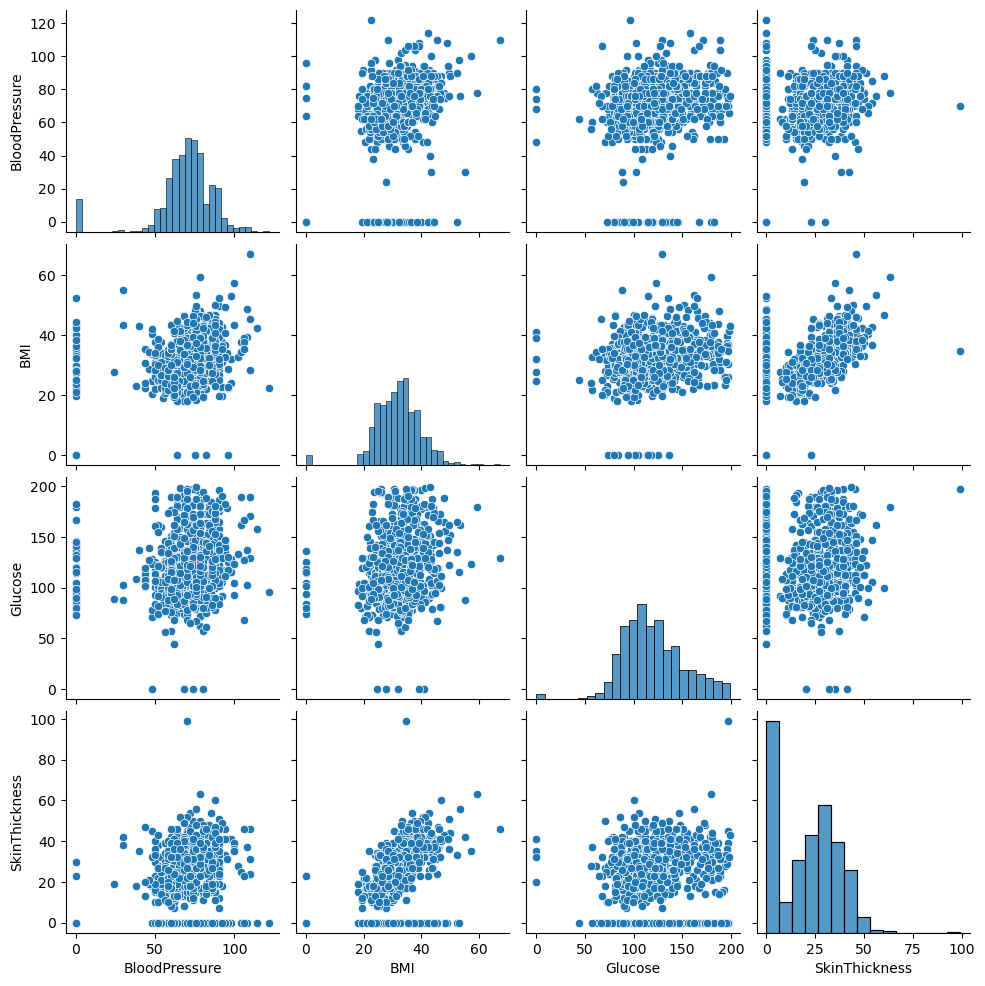

In [16]:
# Define columns with missing values
missing_colsDF = df[['BloodPressure','BMI', 'Glucose', 'SkinThickness']]
    
# Show the pairplot
sns.pairplot(missing_colsDF)
plt.show()

Looking at the charts above we can see all the zero values 

To address the zero values we'll imputate them with median values.

In [17]:
#replacing 0 values with median of that column
df['Glucose']=df['Glucose'].replace(0,df['Glucose'].mean())#normal distribution
df['BloodPressure']=df['BloodPressure'].replace(0,df['BloodPressure'].mean())#normal distribution
df['SkinThickness']=df['SkinThickness'].replace(0,df['SkinThickness'].median())#skewed distribution
df['Insulin']=df['Insulin'].replace(0,df['Insulin'].median())#skewed distribution
df['BMI']=df['BMI'].replace(0,df['BMI'].median())#skewed distribution

#### After Imputation

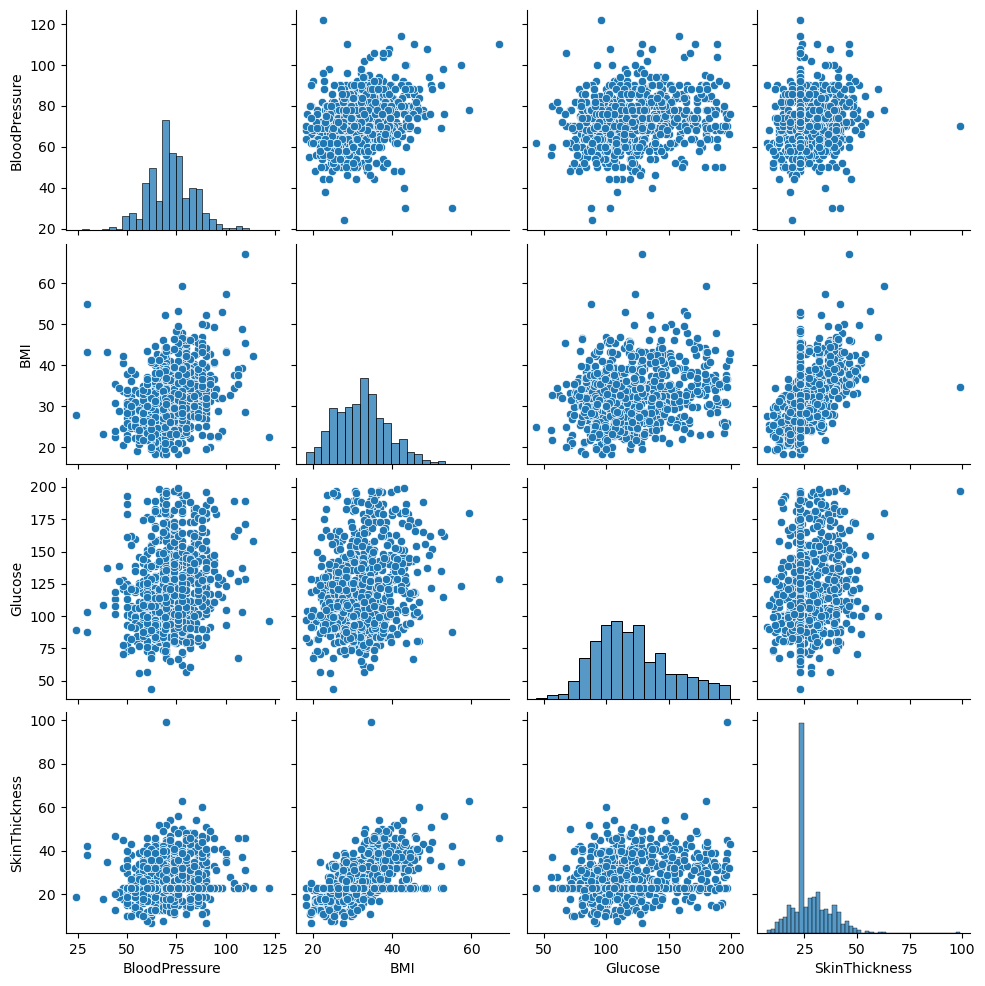

In [18]:
# Define columns with missing values
missing_colsDF = df[['BloodPressure','BMI', 'Glucose', 'SkinThickness']]
    
# Show the pairplot
sns.pairplot(missing_colsDF)
plt.show()

Comparing the before and after imputation charts we can see the disappearance of the zero values givng us more reliable data.

### Data Visualization
Here we are going to plot:
<li>Count Plot: to see if the dataset is balanced or not</li>
<li>Histograms: to see if data is normally distributed or skewed</li>
<li>Box Plot: to analyse the distribution and see the outliers</li>
<li>Scatter plots: to understand relationship between any two variables</li>
<li>Pair plot: to create scatter plot between all the variables</li>

#### Class Imbalance
Next, let's take a look at the proportion of classes. We can view the outcome distrubution and counts with bar and pie charts.  0 = no diabetes while 1 equals diabetes present. 

a:\Anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


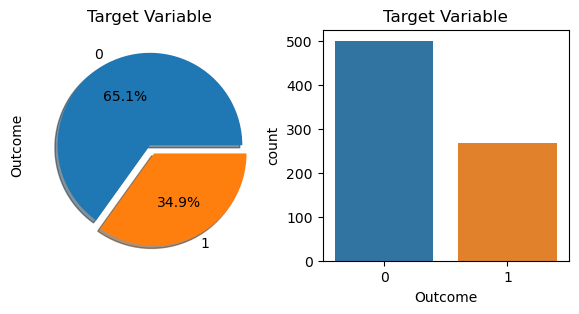

In [19]:
f,ax=plt.subplots(1,2,figsize=(7,3))
df['Outcome'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%',ax=ax[0],shadow=True)
ax[0].set_title('Target Variable')
ax[0].set_ylabel('Outcome')
sns.countplot('Outcome',data=df)
ax[1].set_title('Target Variable')
plt.show()

<b>Conclusion:</b> We observe that number of people who do not have diabetes is far more than people who do which indicates that our data is imbalanced.

## Feature Selection

Pearson's Correlation Coefficient : Helps you find out the relationship between two quantities. It gives you the measure of the strength of association between two variables. The value of Pearson's Correlation Coefficient can be between -1 to +1. 1 means that they are highly correlated and 0 means no correlation.

A heat map is a two-dimensional representation of information with the help of colors. Heat maps can help the user visualize simple or complex information.

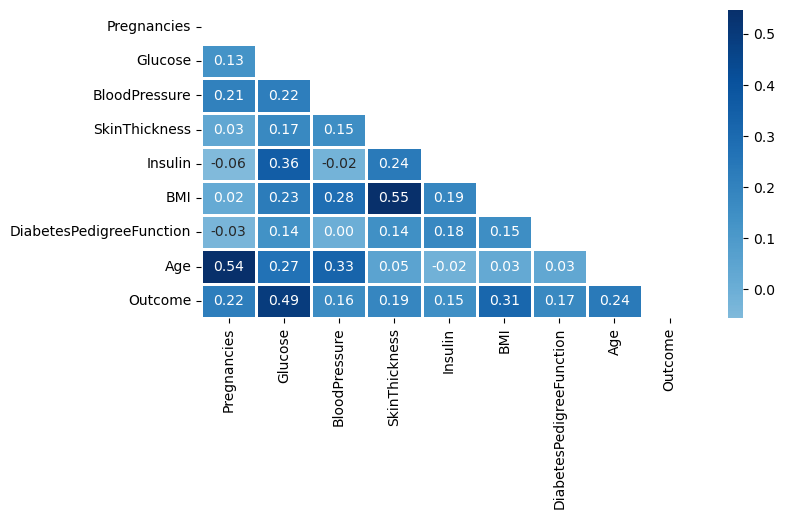

In [20]:
# Create the correlation matrix
corr = df.corr()

# Generate a mask for the upper triangle 
mask = np.triu(np.ones_like(corr, dtype=bool))

# Add the mask to the heatmap
plt.figure(figsize = (8,4))
sns.heatmap(corr, mask=mask, center=0, linewidths=1, annot=True, fmt=".2f", cmap="Blues")
plt.show()

<b>Conclusion:</b> Observe the last row 'Outcome' and note its correlation scores with different features. We can observe that Glucose, BMI and Age are the most correlated with Outcome. BloodPressure, Insulin, DiabetesPedigreeFunction are the least correlated so we can drop them.

In [21]:
#### Drop least correlated features

In [22]:
df_selected=df.drop(['BloodPressure','Insulin','DiabetesPedigreeFunction'],axis='columns')

In [23]:
x=df_selected
quantile  = QuantileTransformer()
X = quantile.fit_transform(x)
df_new=quantile.transform(X)
df_new=pd.DataFrame(X)
#df_new.columns =['Pregnancies', 'Glucose', 'SkinThickness', 'BMI', 'Age']
df_new.columns =['Pregnancies', 'Glucose', 'SkinThickness', 'BMI', 'Age', 'Outcome']
df_new.head()

C:\Users\sschi\AppData\Roaming\Python\Python39\site-packages\sklearn\preprocessing\_data.py:2627: UserWarning: n_quantiles (1000) is greater than the total number of samples (768). n_quantiles is set to n_samples.
  warnings.warn(
C:\Users\sschi\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but QuantileTransformer was fitted with feature names
  warnings.warn(


,Pregnancies,Glucose,SkinThickness,BMI,Age,Outcome
0,0.748,0.810,0.802,0.591,0.890,1.000
1,0.233,0.091,0.645,0.213,0.559,0.000
2,0.864,0.957,0.358,0.078,0.585,1.000
3,0.233,0.125,0.358,0.284,0.000,0.000
4,0.000,0.722,0.802,0.927,0.606,1.000


## Outliers

Outliers are the extreme value within the dataset and can have a big impact on statistical analysis as the can impact calculations like mean and standard deviation. 

First we'll view a quick numerical breakdown followed by histograms and boxpolots.

In [24]:
#outlier_summary(),  count outliers and plot
with open('charts/Outlier_Summary.txt', mode='w', newline='') as outlier_file:
    outlier_writer = csv.writer(outlier_file, delimiter=',', quotechar='"', quoting=csv.QUOTE_MINIMAL)
    for col in df_new.columns: # was feature.cols
        q75, q25 = np.percentile(df[col], [75, 25])
        iqr = q75 - q25
        min_val = q25 - (iqr * 1.5)
        max_val = q75 + (iqr * 1.5)
        count = len(np.where((df[col] > max_val) | (df[col] < min_val))[0])
        percent = round(count / len(df[col]) * 100, 2)

        total_chars = 45
        len_first_chars = 7
        len_col = len(col)
        chars_needed = total_chars - len_col - len_first_chars

        print(len_first_chars * '-' + col + ' Outliers' + chars_needed * '-')
        print('Count: {}'.format(count))
        print('Percentage of Data: {}%'.format(percent))

        outlier_writer.writerow([len_first_chars * '-' + col + ' Outliers' + chars_needed * '-'])
        outlier_writer.writerow(['Count: {}'.format(count)])
        outlier_writer.writerow(['Percentage of Data: {}%'.format(percent)])
        outlier_writer.writerow(' ')

-------Pregnancies Outliers---------------------------
Count: 4
Percentage of Data: 0.52%
-------Glucose Outliers-------------------------------
Count: 0
Percentage of Data: 0.0%
-------SkinThickness Outliers-------------------------
Count: 35
Percentage of Data: 4.56%
-------BMI Outliers-----------------------------------
Count: 8
Percentage of Data: 1.04%
-------Age Outliers-----------------------------------
Count: 9
Percentage of Data: 1.17%
-------Outcome Outliers-------------------------------
Count: 0
Percentage of Data: 0.0%


#### Histogram for Outliers

A histogram is the best way to check univariate data — data containing a single variable — for outliers.

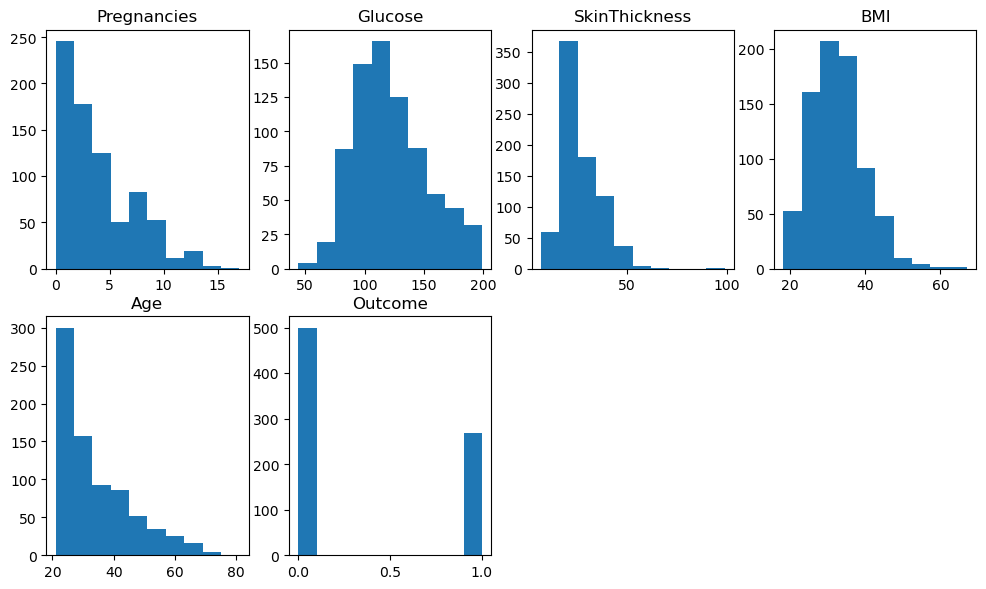

In [25]:
# visualize dist():
plt.figure(figsize=(12, 18))
#for i, col in enumerate(feature_cols, 1):
for i, col in enumerate(df_new.columns, 1):
    plt.subplot(5, 4, i)
    plt.hist(df[col])
    plt.title(col)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
plt.savefig('charts/Visualize_Winsorized.png', dpi=None, facecolor='w', edgecolor='g', orientation='portrait',
            format=None, transparent=False, bbox_inches=None, pad_inches=0.10, metadata=None)
plt.show()


#### Boxplots for Outliers

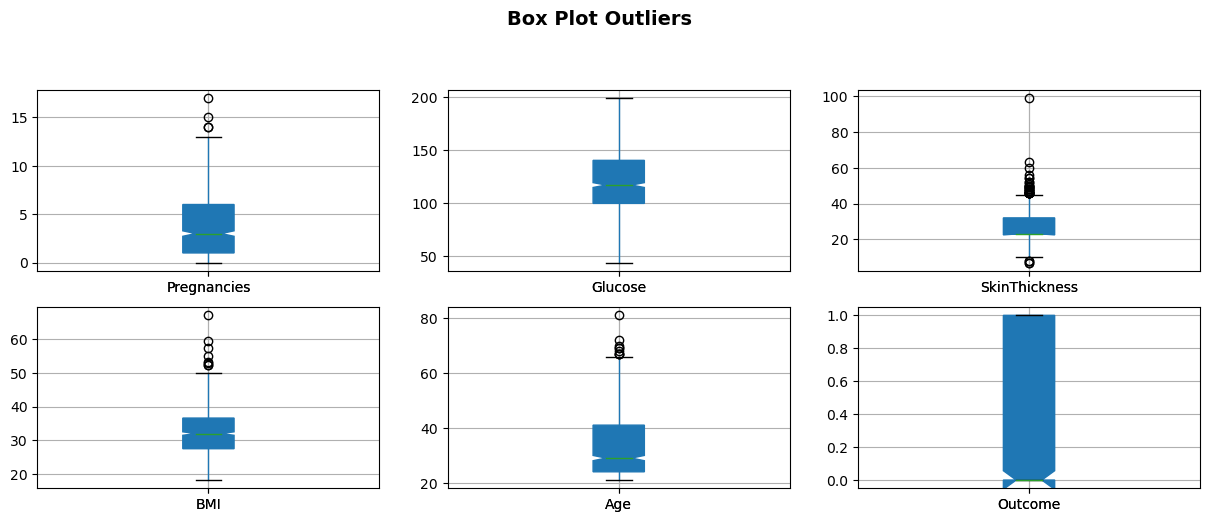

In [27]:
# Box plots for the potential outliers
%matplotlib inline
#outlier_features = ['Adult_Mortality', 'Infant_Deaths', 'BMI', 'Under-Five_Deaths', 'GDP', 'Population']
plt.figure(figsize=(15, 8))
#for i, col in enumerate(feature_cols, start=1):
for i, col in enumerate(df_new.columns, start=1):
    plt.subplot(3, 3, i)
    #plt.xticks([1, 2, 3, 4, 5, 6, 7, 8], df_new.columns)
    plt.xticks([1, 2, 3, 4, 5, 6], df_new.columns)
    df.boxplot(col, notch=True, patch_artist=True)

plt.suptitle('Box Plot Outliers', fontsize=14, verticalalignment='top', horizontalalignment='center',
                fontweight='bold')
plt.savefig('charts/BoxPlot_Outliers.png', dpi=None, facecolor='w', edgecolor='g', orientation='landscape',
            format=None, transparent=False, bbox_inches=None, pad_inches=0.10, metadata=None)
plt.show()

Outliers are unusual values in your dataset, and they can distort statistical analyses and violate their assumptions. Hence it is of utmost importance to deal with them. In this case removing outliers can cause data loss so we have to deal with it using various scaling and transformation techniques.

In [ ]:
scatter_matrix(df,figsize=(20,20));

<b>Conclusion:</b> We can come to various conclusions looking at these plots. For example, if you observe 5th plot in pregnancies with insulin, you can conclude that women with higher number of pregnancies have lower insulin.  

In [41]:
#print(df_new.columns)

#x=df_new.columns
x=df_selected

#for i in range(1, len(df_new.columns)): # specifying 1 here will skip the first row
#    df_new.columns[i] = [float(x) for x in df_new.columns[i]

quantile = QuantileTransformer()
X = quantile.fit_transform(x)
df_new=quantile.transform(X)
df_new=pd.DataFrame(X)
df_new.columns =['Pregnancies', 'Glucose','SkinThickness','BMI','Age','Outcome']
#df_new.columns =['Pregnancies', 'Glucose','SkinThickness','BMI','Age']
df_new.head()

C:\Users\sschi\AppData\Roaming\Python\Python39\site-packages\sklearn\preprocessing\_data.py:2627: UserWarning: n_quantiles (1000) is greater than the total number of samples (768). n_quantiles is set to n_samples.
  warnings.warn(
C:\Users\sschi\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but QuantileTransformer was fitted with feature names
  warnings.warn(


,Pregnancies,Glucose,SkinThickness,BMI,Age,Outcome
0,0.748,0.810,0.802,0.591,0.890,1.000
1,0.233,0.091,0.645,0.213,0.559,0.000
2,0.864,0.957,0.358,0.078,0.585,1.000
3,0.233,0.125,0.358,0.284,0.000,0.000
4,0.000,0.722,0.802,0.927,0.606,1.000


### Windsorization
Let's work with the outliers.

Because there are a number of features with outlier issues and each one has its own unique issues, the method I will use to address outliners is to Winsorize the data.  This method will help to minimize that influence that outliers have on each variable.  Winsorizing the data will enable me to set upper and lower limits on each feature.  This limits the outlier’s severity and influence on the data.  

The parameters for winsorizing will be stored in a dictionary for easy access later in the project.

In [42]:
def winsorizeDF(df: pd.DataFrame) -> pd.DataFrame:
    """
    Replace outliers with 5th and 95th percentile values.
    """
    return df.apply(lambda x: mstats.winsorize(x, limits=[.05, .05]))

# apply winsorize and show summary stats
diabetes_winDF = winsorizeDF(df.drop('Outcome', axis=1))
diabetesDF = diabetes_winDF.join(df['Outcome'])
display(diabetesDF.describe())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.742,121.663,72.027,27.154,87.448,32.328,0.457,32.952,0.349
std,3.124,28.717,10.463,8.115,79.141,6.208,0.277,11.007,0.477
min,0.000,80.000,52.000,14.000,30.500,22.200,0.140,21.000,0.000
25%,1.000,99.750,64.000,23.000,30.500,27.500,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,31.250,32.000,0.372,29.000,0.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,10.000,181.000,90.000,44.000,293.000,44.500,1.136,58.000,1.000


In [ ]:
plt.figure(figsize=(16,12))
sns.set_style(style='whitegrid')
plt.subplot(3,3,1)
sns.boxplot(x=df_new['Glucose'],data=df_new)
plt.subplot(3,3,2)
sns.boxplot(x=df_new['BMI'],data=df_new)
plt.subplot(3,3,3)
sns.boxplot(x=df_new['Pregnancies'],data=df_new)
plt.subplot(3,3,4)
sns.boxplot(x=df_new['Age'],data=df_new)
plt.subplot(3,3,5)
sns.boxplot(x=df_new['SkinThickness'],data=df_new)

Outliers have been replaced!

Outliers have been replaced and we can see the big difference it's made with features such as insulin and skinthickness, for instance. After removing outliers the insulin max has been brought down from 846 to 293 and the skinthickness max is down from 99 to 44.

## Train, Test, and Evaluate Model 
So here we are, ready to model and predict!  In this section we'll walk through logistical regression, linear regression, multiple regression, polynomial regression, decision tree, random forest.

### Create Training Data

Let's split the dataset by using the function train_test_split(). You need to pass three parameters features; target, and test_set size.

In [ ]:
target_name='Outcome'
y= df_new[target_name]#given predictions - training data 
X=df_new.drop(target_name,axis=1)#dropping the Outcome column and keeping all other columns as X

In [ ]:
X.head() # contains only independent features 

In [ ]:
y.head() #contains dependent feature

In [ ]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=0)#splitting data in 80% train, 20%test

In [ ]:
X_train.shape,y_train.shape

In [ ]:
X_test.shape,y_test.shape

## Classification Algorithms

<li>KNN</li>
<li>Naive Bayes</li>
<li>SVM</li>
<li>Decision Tree</li>
<li>Random Forest</li>
<li>Logistic Regression</li>

### Nearest Neighbours
KNN algorithm, is a non-parametric algorithm that classifies data points based on their proximity and association to other available data.

In [ ]:
# List Hyperparameters to tune
knn= KNeighborsClassifier()
n_neighbors = list(range(15,25))
p=[1,2]
weights = ['uniform', 'distance']
metric = ['euclidean', 'manhattan', 'minkowski']

# Convert to dictionary
hyperparameters = dict(n_neighbors=n_neighbors, p=p,weights=weights,metric=metric)

# Making model
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=knn, param_grid=hyperparameters, n_jobs=-1, cv=cv, scoring='f1',error_score=0)

In [ ]:
best_model = grid_search.fit(X_train,y_train)

In [ ]:
# Best Hyperparameters Value
print('Best leaf_size:', best_model.best_estimator_.get_params()['leaf_size'])
print('Best p:', best_model.best_estimator_.get_params()['p'])
print('Best n_neighbors:', best_model.best_estimator_.get_params()['n_neighbors'])

In [ ]:
# Predict testing set
knn_pred = best_model.predict(X_test)

In [ ]:
print("Classification Report is:\n",classification_report(y_test,knn_pred))
print("\n F1:\n",f1_score(y_test,knn_pred))
print("\n Precision score is:\n",precision_score(y_test,knn_pred))
print("\n Recall score is:\n",recall_score(y_test,knn_pred))
print("\n Confusion Matrix:\n")
sns.heatmap(confusion_matrix(y_test,knn_pred))

## Naive Bayes

Naive Bayes is classification approach that adopts the principle of class conditional independence from the Bayes Theorem. This means that the presence of one feature does not impact the presence of another in the probability of a given outcome, and each predictor has an equal effect on that result

In [ ]:
param_grid_nb = {
    'var_smoothing': np.logspace(0,-2, num=100)
}
nbModel_grid = GridSearchCV(estimator=GaussianNB(), param_grid=param_grid_nb, verbose=1, cv=10, n_jobs=-1)

In [ ]:
best_model= nbModel_grid.fit(X_train, y_train)

In [ ]:
nb_pred=best_model.predict(X_test)

In [ ]:
print("Classification Report is:\n",classification_report(y_test,nb_pred))
print("\n F1:\n",f1_score(y_test,nb_pred))
print("\n Precision score is:\n",precision_score(y_test,nb_pred))
print("\n Recall score is:\n",recall_score(y_test,nb_pred))
print("\n Confusion Matrix:\n")
sns.heatmap(confusion_matrix(y_test,nb_pred))

## Support Vector Machine
It is typically leveraged for classification problems, constructing a hyperplane where the distance between two classes of data points is at its maximum. This hyperplane is known as the decision boundary, separating the classes of data points (e.g., has diabetes vs doesn't have diabetes ) on either side of the plane.

In [ ]:
model = SVC()
kernel = ['poly', 'rbf', 'sigmoid']
C = [50, 10, 1.0, 0.1, 0.01]
gamma = ['scale']

In [ ]:
# define grid search
grid = dict(kernel=kernel,C=C,gamma=gamma)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
grid_search = GridSearchCV(estimator=model, param_grid=grid, n_jobs=-1, cv=cv, scoring='f1',error_score=0)

In [ ]:
grid_result = grid_search.fit(X, y)

In [ ]:
svm_pred=grid_result.predict(X_test)

In [ ]:
print("Classification Report is:\n",classification_report(y_test,svm_pred))
print("\n F1:\n",f1_score(y_test,knn_pred))
print("\n Precision score is:\n",precision_score(y_test,knn_pred))
print("\n Recall score is:\n",recall_score(y_test,knn_pred))
print("\n Confusion Matrix:\n")
sns.heatmap(confusion_matrix(y_test,svm_pred))

## Decision Tree
Let's create a decision tree model using Scikit-learn

In [ ]:
# Create the parameter grid based on the results of random search 
params = {
    'max_depth': [5, 10, 20,25],
    'min_samples_leaf': [10, 20, 50, 100,120],
    'criterion': ["gini", "entropy"]
}

In [ ]:
grid_search = GridSearchCV(estimator=dt, 
                           param_grid=params, 
                           cv=4, n_jobs=-1, verbose=1, scoring = "accuracy")

In [ ]:
best_model=grid_search.fit(X_train, y_train)

In [ ]:
dt_pred=best_model.predict(X_test)

In [ ]:
print("Classification Report is:\n",classification_report(y_test,dt_pred))
print("\n F1:\n",f1_score(y_test,dt_pred))
print("\n Precision score is:\n",precision_score(y_test,dt_pred))
print("\n Recall score is:\n",recall_score(y_test,dt_pred))
print("\n Confusion Matrix:\n")
sns.heatmap(confusion_matrix(y_test,dt_pred))

In [ ]:
# Feature variables
x=df.drop(['Outcome'], axis=1)
x

print(x)

In [ ]:
#target variable
y=df.Outcome
y

print(y)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [ ]:
# Create Decision Tree classifer object
model = DecisionTreeClassifier()

# Train Decision Tree Classifer
model = model.fit(X_train,y_train)

# Predict the response for test dataset
y_pred = model.predict(X_test) 

print("Accuracy:",metrics.accuracy_score(y_test, y_pred)*100)

In [ ]:
confusion_matrix(y_test,y_pred)

In [ ]:
print("Accuracy:",((82+27)/154))

In [ ]:
print(classification_report(y_test,y_pred))

In [ ]:
#checking prediction value
print(df_selected)
model.predict([[6,148,72,35,0,33.6,0.627,50]])

In [ ]:
features=x.columns
features

In [ ]:
dot_data = StringIO()
export_graphviz(model, out_file=dot_data,filled=True, rounded=True,special_characters=True,feature_names = features,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes_set.png')
Image(graph.create_png())

Next we can use ProfileReport to do a quick EDA as an extended analysis of the dataframe.

In [ ]:
profile = ProfileReport(df, title="Diabetes Classification")
profile